# Insurance prediction with five Regressor Models

### Adding libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")



### Reading the dataset, Data Overview

In [ ]:
df= pd.read_csv("./insurance.csv")

df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [ ]:
df.info()
#null 없음. sex, smoker, region은 문자형. 나머지는 숫자 

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [ ]:
df.describe()
#수치형 변수들의 요약통계량


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.shape
#7개 피처 

(1338, 7)

### Checking the missing data

In [ ]:
df.isnull().sum().sort_values(ascending= False)


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

### Distribution Plot

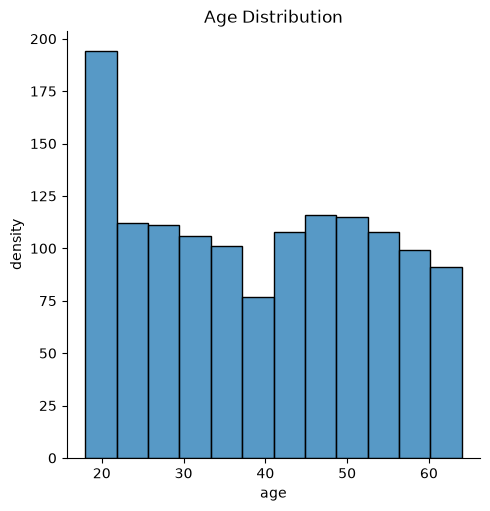

In [ ]:
sns.displot(df['age']) #age 변수의 분포를 그림. 기본은 히스토그램.
plt.title('Age Distribution')
plt.ylabel('density')
plt.xlabel('age')
plt.show()

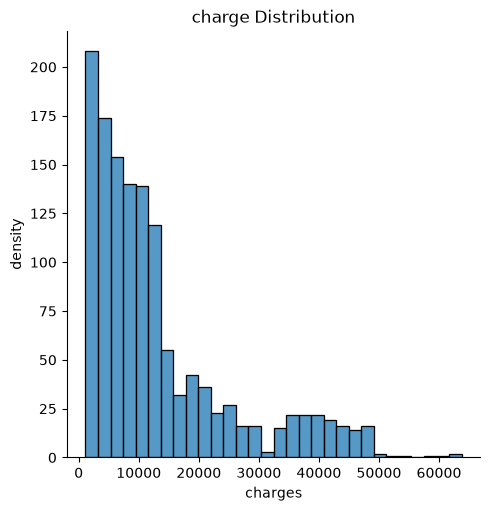

In [ ]:
sns.displot(df['charges'])
plt.title('charge Distribution')
plt.ylabel('density')
plt.xlabel('charges')
plt.show()

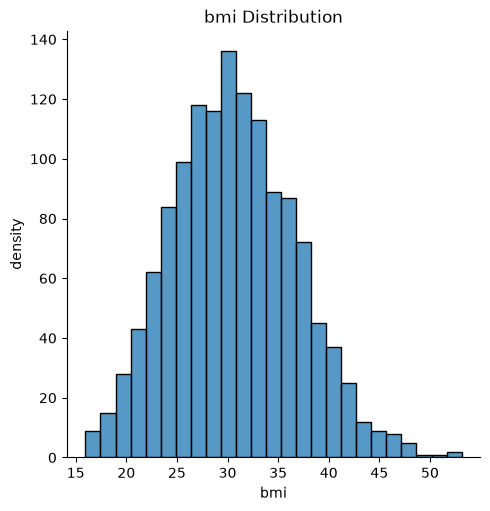

In [ ]:
sns.displot(df['bmi']) 
plt.title('bmi Distribution')
plt.ylabel('density')
plt.xlabel('bmi')
plt.show()

### Count Plot

In [ ]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

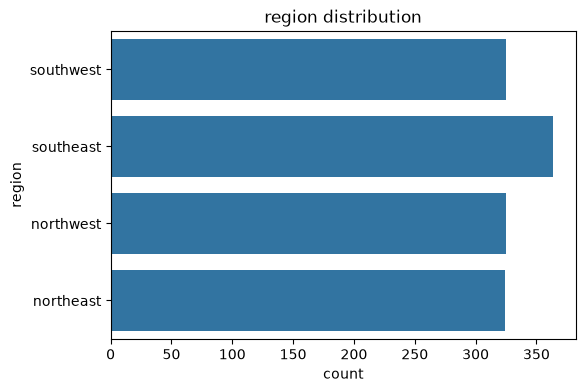

In [ ]:
fig= plt.figure(figsize=(6,4))
sns.countplot(df['region'])
plt.title('region distribution')
plt.show()

In [ ]:
df['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

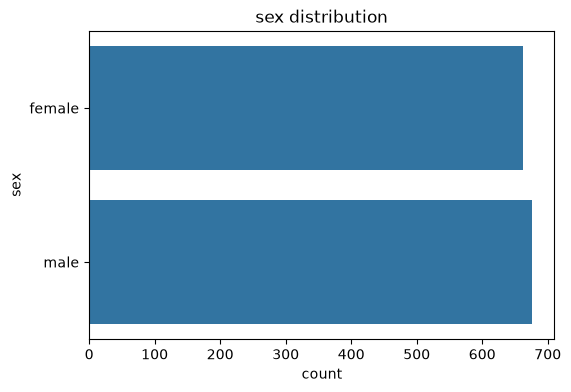

In [ ]:
fig = plt.figure(figsize = (6,4))
sns.countplot(df['sex'])
plt.title('sex distribution')
plt.show()

In [ ]:
df['children'].value_counts()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

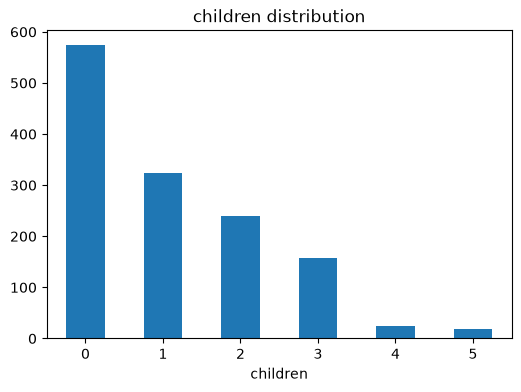

In [ ]:
fig = plt.figure(figsize = (6,4))
df['children'].value_counts().plot(kind="bar") #Pandas에서 그림. 빈도를 직접 계산-> 그래프
#sns.countplot(df['children']): Seaborn 라이브러리에서 그림. 빈도 자동 계산

plt.title('children distribution')
plt.xticks(rotation = 0)
plt.show()

### Checking the correlation

In [ ]:
#pd.factorize(df['sex']) : 각 범주에 숫자 부여
#pd.factorize(df['sex'])[0] : 반환값 중 숫자로 인코딩된 배열만 가져옴. 
#pd.factorize(df['sex'])[1] : 원래 범주 목록


Index(['female', 'male'], dtype='str')

In [ ]:
df['sex']=pd.factorize(df['sex'])[0]+1 #남, 여를 각각 1,2로 변환해서 df에 넣기 
df['region']=pd.factorize(df['region'])[0]+1  #1,2,3,4로 인코딩
df['smoker']=pd.factorize(df['smoker'])[0]+1  #

corr= df.corr()
corr['charges'].sort_values(ascending=False) #각 피처와 charges와의 상관관계 

charges     1.000000
age         0.299008
bmi         0.198341
children    0.067998
sex         0.057292
region      0.006208
smoker     -0.787251
Name: charges, dtype: float64

### Correlation Plot

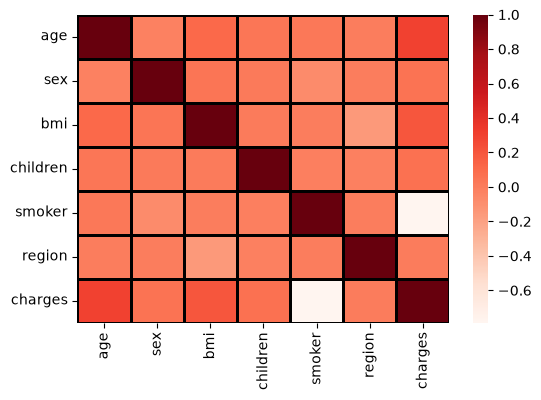

In [ ]:
fig= plt.figure(figsize=(6,4))
data_ploting= df.corr(method= 'pearson')
sns.heatmap(data_ploting, cmap='Reds', linecolor='black', linewidths=2)
#히트맵은 데이터의 크기를 색깔로 표현하는 그래프. 상관계수의 값에 따라 색을 다르게 표현하는 그래프 생성. 
plt.show()

### Pair Plot

<Figure size 600x400 with 0 Axes>

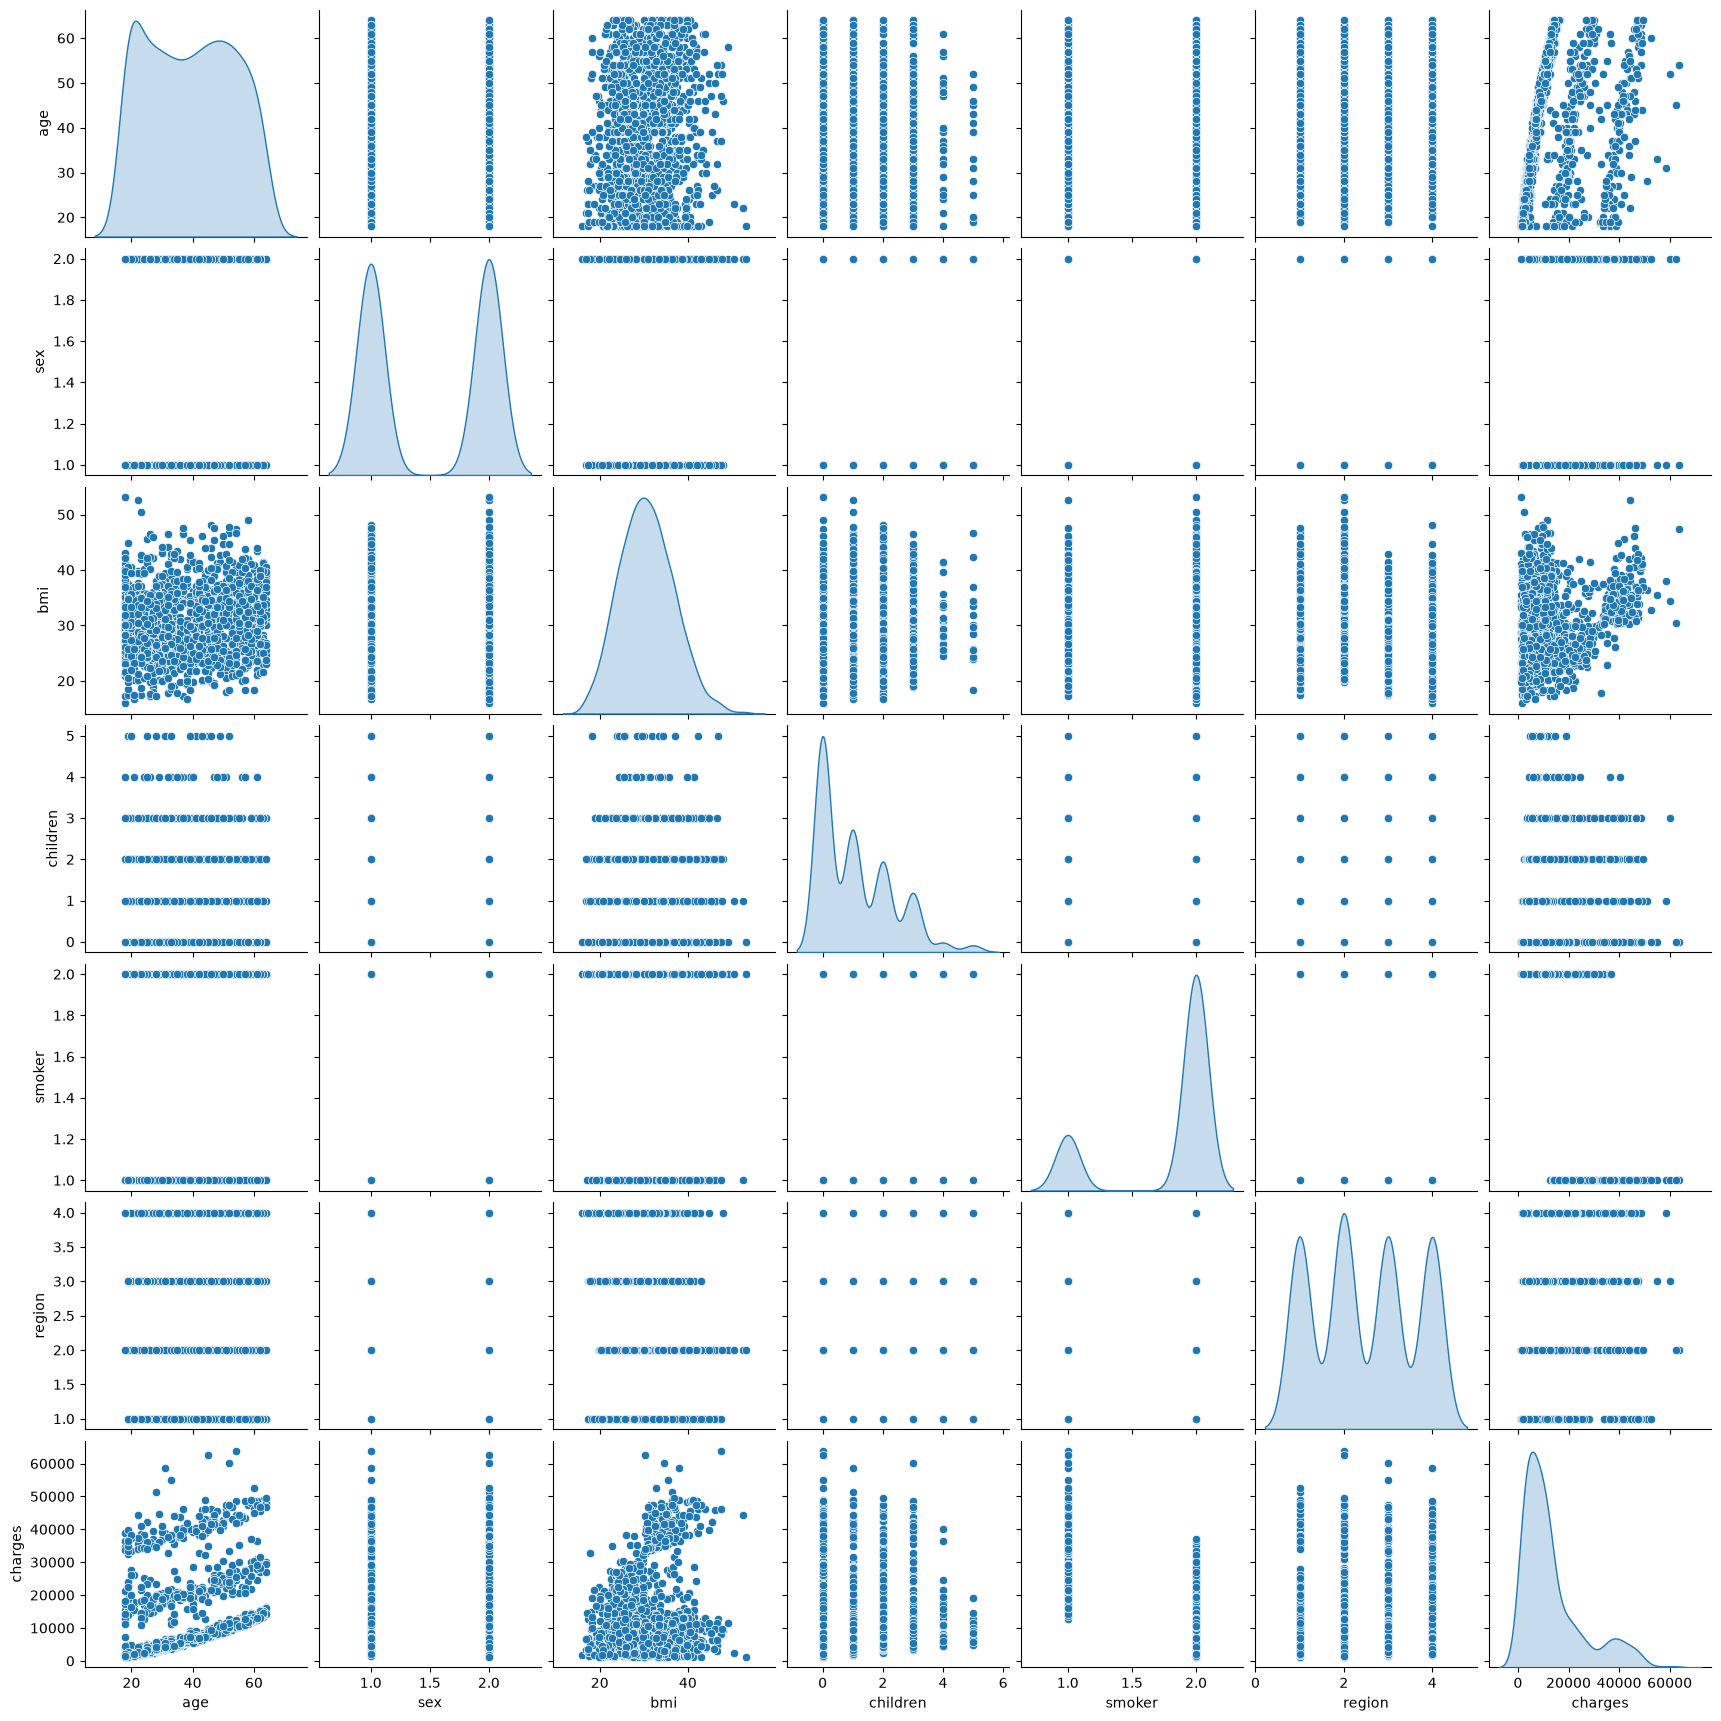

In [ ]:
fig= plt.figure(figsize=(6,4))
sns.pairplot(df, diag_kind='kde');

### Train and Test Split, Scalling data

In [ ]:
X= df.drop('charges', axis=1)
y=df['charges']
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.3, random_state=101)

scaler= StandardScaler()
scaler.fit(X_train)
X_train_scaled= scaler.transform(X_train)
X_test_scaled= scaler.transform(X_test)

### 1. Linear Regression Model

In [ ]:
linear_reg_model= LinearRegression()
linear_reg_model.fit(X_train_scaled, y_train);

In [ ]:
y_pred= linear_reg_model.predict(X_test_scaled)
y_pred= pd.DataFrame(y_pred)
MAE_li_reg= metrics.mean_absolute_error(y_test, y_pred)
MSE_li_reg = metrics.mean_squared_error(y_test, y_pred)
RMSE_li_reg =np.sqrt(MSE_li_reg)
pd.DataFrame([MAE_li_reg, MSE_li_reg, RMSE_li_reg], index=['MAE_li_reg', 'MSE_li_reg', 'RMSE_li_reg'], columns=['Metrics'])

,Metrics
MAE_li_reg,3.990250e+03
MSE_li_reg,3.353013e+07
RMSE_li_reg,5.790521e+03


In [ ]:
scores = cross_val_score(linear_reg_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))

[0.88791389 0.85653048 0.84404195 0.87198372 0.84417492]


In [ ]:
r2_score(y_test, linear_reg_model.predict(X_test_scaled))

0.7613126015198817

### 2. Gradient Boosting Regressor Model

In [ ]:
Gradient_model = GradientBoostingRegressor()
Gradient_model.fit(X_train_scaled, y_train);

In [ ]:
y_pred = Gradient_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)
MAE_gradient= metrics.mean_absolute_error(y_test, y_pred)
MSE_gradient = metrics.mean_squared_error(y_test, y_pred)
RMSE_gradient =np.sqrt(MSE_gradient)
pd.DataFrame([MAE_gradient, MSE_gradient, RMSE_gradient], index=['MAE_gradient', 'MSE_gradient', 'RMSE_gradient'], columns=['Metrics'])

,Metrics
MAE_gradient,2.526184e+03
MSE_gradient,2.110072e+07
RMSE_gradient,4.593552e+03


In [ ]:
scores = cross_val_score(Gradient_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))

[0.94592184 0.91460859 0.91670131 0.92156263 0.91716787]


In [ ]:
r2_score(y_test, Gradient_model.predict(X_test_scaled))

0.849792542412332

### 3. XGB Regressor Mode

In [ ]:
XGB_model =XGBRegressor()
XGB_model.fit(X_train_scaled, y_train);

In [ ]:
y_pred = XGB_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)
MAE_XGB= metrics.mean_absolute_error(y_test, y_pred)
MSE_XGB = metrics.mean_squared_error(y_test, y_pred)
RMSE_XGB =np.sqrt(MSE_XGB)
pd.DataFrame([MAE_XGB, MSE_XGB, RMSE_XGB], index=['MAE_XGB', 'MSE_XGB', 'RMSE_XGB'], columns=['Metrics'])

,Metrics
MAE_XGB,3.198314e+03
MSE_XGB,3.061846e+07
RMSE_XGB,5.533395e+03


In [ ]:
scores = cross_val_score(XGB_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))

[0.90787759 0.88795747 0.91289956 0.89459789 0.88672783]


In [ ]:
r2_score(y_test, XGB_model.predict(X_test_scaled))

0.7820396260594861

### 4. Decision Tree Regressor Model

In [ ]:
tree_reg_model =DecisionTreeRegressor()
tree_reg_model.fit(X_train_scaled, y_train);

In [ ]:
y_pred = tree_reg_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)
MAE_tree_reg= metrics.mean_absolute_error(y_test, y_pred)
MSE_tree_reg = metrics.mean_squared_error(y_test, y_pred)
RMSE_tree_reg =np.sqrt(MSE_tree_reg)
pd.DataFrame([MAE_tree_reg, MSE_tree_reg, RMSE_tree_reg], index=['MAE_tree_reg', 'MSE_tree_reg', 'RMSE_tree_reg'], columns=['Metrics'])

,Metrics
MAE_tree_reg,3.584389e+03
MSE_tree_reg,5.173228e+07
RMSE_tree_reg,7.192515e+03


In [ ]:
scores = cross_val_score(tree_reg_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))

[0.84259007 0.81260523 0.84986817 0.85775015 0.85668693]


In [ ]:
r2_score(y_test, tree_reg_model.predict(X_test_scaled))

0.6317389024764529

### 5. Random Forest Regressor Model

In [ ]:
forest_reg_model =RandomForestRegressor()
forest_reg_model.fit(X_train_scaled, y_train);

In [ ]:
y_pred = forest_reg_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)
MAE_forest_reg= metrics.mean_absolute_error(y_test, y_pred)
MSE_forest_reg = metrics.mean_squared_error(y_test, y_pred)
RMSE_forest_reg =np.sqrt(MSE_forest_reg)
pd.DataFrame([MAE_forest_reg, MSE_forest_reg, RMSE_forest_reg], index=['MAE_forest_reg', 'MSE_forest_reg', 'RMSE_forest_reg'], columns=['Metrics'])

,Metrics
MAE_forest_reg,2.847608e+03
MSE_forest_reg,2.485854e+07
RMSE_forest_reg,4.985834e+03


In [ ]:
scores = cross_val_score(forest_reg_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))

[0.94281543 0.90581447 0.92233098 0.91256986 0.90323147]


In [ ]:
r2_score(y_test, forest_reg_model.predict(X_test_scaled))

0.8230421299085562